# 5. Same screen, same answer? (reproducibility)

**Why this matters.** Cloud oracles call a hosted model that can change without notice. Ju et al. 2024 report GPT-4 falling from 43.7% to 1% correct between May and July 2024 with the same prompt. C3 runs frozen weights on the laptop, so the same screen should get the same answer every time.

**What was done.** The C3 v3 adapter was run on the 425 test screens on 21 Oct 2026 and again on 6 Nov 2026, with the same code, prompt, seed and GPU. The 122 test defects were also re-run through full generation (type and box). This notebook compares the two runs screen by screen.

Nothing is re-run here: every number is read from saved files. Run all cells (a few seconds).

In [1]:
import json, statistics, sys
from pathlib import Path
import matplotlib.pyplot as plt

C3 = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'evidence' / '16_reproducibility').exists())
sys.path.insert(0, str(C3))   # use this repo's module, not an older installed copy
from local_vision_oracle.reproducibility import compare_scores, compare_e2e, screen_key
OLD, NEW = C3 / 'evidence' / '15_model_v3', C3 / 'evidence' / '16_reproducibility'
def records(path): return json.loads(path.read_text(encoding='utf-8'))['records']

THRESHOLD = 0.30075   # chosen on the validation set in EXP-09
s_old, s_new = records(OLD / 'v3_test_scores.json'), records(NEW / 'v3_test_scores_rerun.json')
e_old, e_new = records(OLD / 'v3_e2e_defects122.json'), records(NEW / 'v3_e2e_defects122_rerun.json')
score = compare_scores(s_old, s_new, THRESHOLD)
e2e = compare_e2e(e_old, e_new)
print(f"Screens compared: {score['screens']}")
print(f"Largest change in P(defect): {score['max_abs_diff']}")
print(f"Verdicts that flipped at threshold {THRESHOLD}: {len(score['verdict_flips'])}")
print(f"Generated answers identical (122 defects): {e2e['raw_text_identical']:.0%}  type {e2e['type_agreement']:.0%}  box {e2e['box_identical']:.0%}")

Screens compared: 425
Largest change in P(defect): 0.0
Verdicts that flipped at threshold 0.30075: 0
Generated answers identical (122 defects): 100%  type 100%  box 100%


## Look at this: every dot on the diagonal
Each dot is one test screen. Horizontal = defect probability on 21 Oct; vertical = on 6 Nov. If the model were unstable, dots would scatter off the red line.

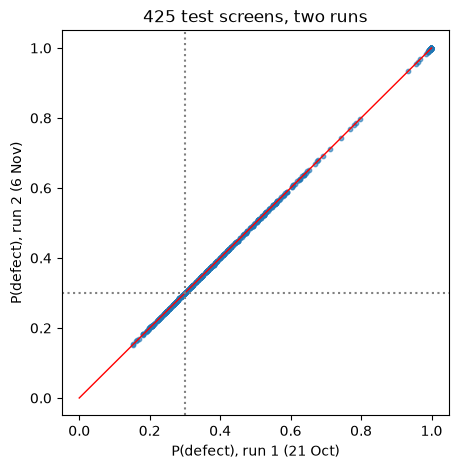

In [2]:
old = {screen_key(r['image']): r['p_defect'] for r in s_old}
new = {screen_key(r['image']): r['p_defect'] for r in s_new}
keys = sorted(old)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter([old[k] for k in keys], [new[k] for k in keys], s=10, alpha=.6)
ax.plot([0, 1], [0, 1], 'r-', lw=1)
ax.axvline(THRESHOLD, color='grey', ls=':'); ax.axhline(THRESHOLD, color='grey', ls=':')
ax.set_xlabel('P(defect), run 1 (21 Oct)'); ax.set_ylabel('P(defect), run 2 (6 Nov)')
ax.set_title('425 test screens, two runs'); plt.show()

## But speed was not the same
The answers repeat exactly; the time taken did not. Same GPU and code, different day. Latency must therefore be reported with repeated runs and the machine state, not as one number.

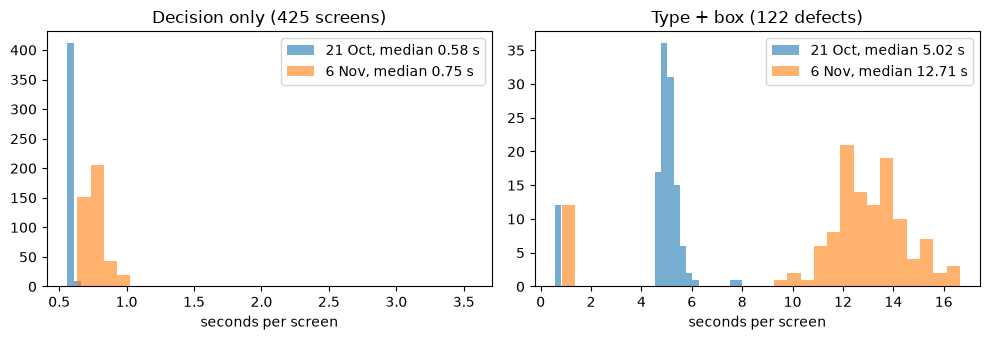

In [3]:
def lat(recs): return [r['latency_ms'] / 1000 for r in recs]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (a, b, title) in zip(axes, [(s_old, s_new, 'Decision only (425 screens)'), (e_old, e_new, 'Type + box (122 defects)')]):
    ax.hist(lat(a), bins=30, alpha=.6, label=f"21 Oct, median {statistics.median(lat(a)):.2f} s")
    ax.hist(lat(b), bins=30, alpha=.6, label=f"6 Nov, median {statistics.median(lat(b)):.2f} s")
    ax.set_xlabel('seconds per screen'); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

## What to conclude
1. **Answers are reproducible:** 425 of 425 scores identical to the stored digits, 0 verdict flips, and 122 of 122 generated answers identical (text, type and box). This supports a measured contrast with hosted-model drift reported by Ju et al. 2024.
2. **This is not accuracy.** The model repeats its mistakes too: about half of clean screens are still flagged, and tight boxes are still 6.6%.
3. **Latency is not stable across days.** Decision median 0.58 s then 0.75 s; type and box 5.0 s then 12.7 s. The cause was not identified. Report latency as a distribution over repeated runs with the power and thermal state recorded.